### **Fingerprint Enhancement with Morphology**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/Fingerprint_Enhancement.ipynb)

> Fingerprint recognition depends on clean ridges. This image has impulsive noise: white specks in the valleys and black specks on the ridges. An **opening** removes the white specks, and a **closing** then fills the black ones, giving cleaner ridges for later steps such as thinning and minutiae extraction.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [2]:
# Load the fingerprint as a binary image
fingerprint = load_image("Fingerprint.jpg", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(fingerprint, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Image size:", binary.shape)

Image size: (305, 400)


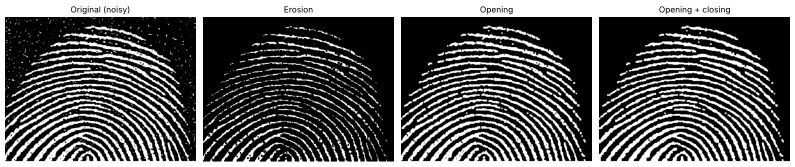

In [3]:
# Opening, then closing, with a small 3x3 structuring element
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
show([binary, cv2.erode(binary, kernel), opened, cleaned],
     ["Original (noisy)", "Erosion", "Opening", "Opening + closing"], size=(16, 4.5))

White fragments (original): 381
White fragments (cleaned): 37


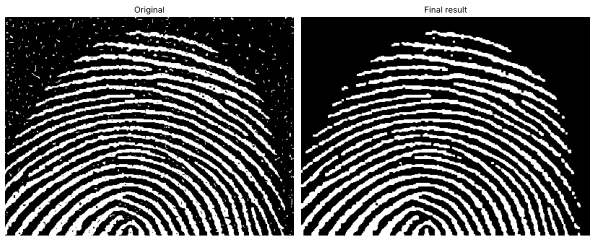

In [4]:
# Measure the cleanup: number of separate white fragments before and after
for name, image in [("original", binary), ("cleaned", cleaned)]:
    count = cv2.connectedComponents(image)[0] - 1
    print(f"White fragments ({name}): {count}")
show([binary, cleaned], ["Original", "Final result"], size=(12, 5))

#### **Key Takeaways**

* Opening followed by closing removes impulsive noise on both sides of the ridges.
* A 3×3 element is enough here; larger elements would merge neighboring ridges.
* Counting fragments gives an objective measure of the cleanup.